# Toy Transformer from Scratch (PyTorch)

A small, educational **decoder-only Transformer** that learns next-character prediction from a tiny text corpus.


## 1. Imports and reproducibility

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


## 2. Create a tiny training corpus

We'll train on a few short sentences. The model predicts the **next character** given previous characters.

In [2]:
text = (
    "the cat sat on the mat. "
    "the cat ate a fish. "
    "a dog sat on the rug. "
    "the dog chased the cat. "
    "cats and dogs are animals. "
) * 100

chars = sorted(set(text))
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(chars)

def encode(s):
    return [stoi[ch] for ch in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data, val_data = data[:split], data[split:]

print("Vocabulary size:", vocab_size)
print("Example encoding:", encode("the"))
print("Decoded back:", decode(encode("the")))

Vocabulary size: 18
Example encoding: [16, 8, 5]
Decoded back: the


## 3. Prepare training batches

Each input sequence contains characters, and its target is the same sequence shifted one character to the right.

In [ ]:
block_size = 32  # number of previous characters the model can see

def get_batch(split_name, batch_size=32):
    source = train_data if split_name == "train" else val_data
    starts = torch.randint(0, len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[i:i+block_size] for i in starts])
    y = torch.stack([source[i+1:i+block_size+1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input shape:", xb.shape)   
print("Target shape:", yb.shape)
print("Input example:", decode(xb[0].tolist()))
print("Target example:", decode(yb[0].tolist()))

Input shape: torch.Size([32, 32])
Target shape: torch.Size([32, 32])
Input example: ish. a dog sat on the rug. the d
Target example: sh. a dog sat on the rug. the do


## 4. Implement causal self-attention


In [ ]:
class SelfAttentionHead(nn.Module):
    def __init__(self, n_embd, head_size, block_size, dropout=0.1):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)       
        q = self.query(x)     
        v = self.value(x)     

        scores = q @ k.transpose(-2, -1) * (k.shape[-1] ** -0.5)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        out = weights @ v
        return out, weights

# Quick shape check
demo_head = SelfAttentionHead(n_embd=16, head_size=8, block_size=block_size).to(device)
demo_x = torch.randn(2, 10, 16, device=device)
demo_out, demo_weights = demo_head(demo_x)
print("Input:", demo_x.shape)
print("Attention output:", demo_out.shape)
print("Attention weights:", demo_weights.shape)

Input: torch.Size([2, 10, 16])
Attention output: torch.Size([2, 10, 8])
Attention weights: torch.Size([2, 10, 10])


## 5. Multi-head attention

Each head can learn a different pattern. We concatenate the outputs and project them back to the model embedding size.

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, num_heads, block_size, dropout=0.1):
        super().__init__()
        assert n_embd % num_heads == 0
        head_size = n_embd // num_heads
        self.heads = nn.ModuleList([
            SelfAttentionHead(n_embd, head_size, block_size, dropout)
            for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        head_outputs = [head(x)[0] for head in self.heads]
        out = torch.cat(head_outputs, dim=-1)
        return self.dropout(self.proj(out))

mha = MultiHeadAttention(n_embd=16, num_heads=4, block_size=block_size).to(device)
print("Multi-head output shape:", mha(demo_x).shape)

Multi-head output shape: torch.Size([2, 10, 16])


## 6. Feed-forward network and Transformer block

In [6]:
class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, num_heads, block_size, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadAttention(n_embd, num_heads, block_size, dropout)
        self.ffn = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # Pre-norm residual connections
        x = x + self.attention(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

## 7. Build the tiny language model

The model combines token embeddings and positional embeddings, passes them through Transformer blocks, and predicts a probability distribution over the next character.

In [ ]:
class TinyTransformer(nn.Module):
    def __init__(
        self, vocab_size, n_embd=64, num_heads=4,
        num_layers=2, block_size=32, dropout=0.1
    ):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[
            TransformerBlock(n_embd, num_heads, block_size, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.block_size:
            raise ValueError("Input sequence is longer than block_size")

        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)  # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(B * T, -1),
                targets.reshape(B * T)
            )
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=100, temperature=1.0):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)
        return idx


model = TinyTransformer(
    vocab_size=vocab_size,
    n_embd=64,
    num_heads=4,
    num_layers=2,
    block_size=block_size,
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total_params:,}")
logits, loss = model(xb, yb)
print("Logits shape:", logits.shape)  
print("Initial loss:", round(loss.item(), 4))

Parameters: 104,082
Logits shape: torch.Size([32, 32, 18])
Initial loss: 3.0832


## 8. Train the model

Cross-entropy loss measures how well the model predicts the next character. The optimizer updates the model's parameters to reduce that loss.

In [8]:
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)
max_steps = 1000
eval_interval = 200

@torch.no_grad()
def estimate_loss():
    model.eval()
    results = {}
    for split_name in ("train", "val"):
        losses = []
        for _ in range(10):
            x, y = get_batch(split_name)
            _, batch_loss = model(x, y)
            losses.append(batch_loss.item())
        results[split_name] = sum(losses) / len(losses)
    model.train()
    return results

model.train()
for step in range(max_steps):
    x, y = get_batch("train")
    _, loss = model(x, y)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

    if step % eval_interval == 0 or step == max_steps - 1:
        metrics = estimate_loss()
        print(
            f"Step {step:4d} | "
            f"train loss {metrics['train']:.3f} | "
            f"val loss {metrics['val']:.3f}"
        )

Step    0 | train loss 2.694 | val loss 2.676
Step  200 | train loss 0.092 | val loss 0.093
Step  400 | train loss 0.081 | val loss 0.074
Step  600 | train loss 0.080 | val loss 0.080
Step  800 | train loss 0.082 | val loss 0.077
Step  999 | train loss 0.077 | val loss 0.079


## 9. Generate text

The model starts from a prompt and repeatedly predicts one next character.

In [16]:
prompt = "a cat"
context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
generated = model.generate(context, max_new_tokens=200, temperature=0.8)
print(decode(generated[0].tolist()))

a cat sat on the mat. the cat ate a fish. a dog sat on the rug. the dog chased the cat. cats and dogs are animals. the cat sat on the mat. the cat ate a fish. a dog sat on the rug. the dog chased the cat. 


## 10. Inspect attention weights 

Attention weights show which earlier positions each token attends to in a selected head. Because this model uses causal attention, positions to the right are masked.


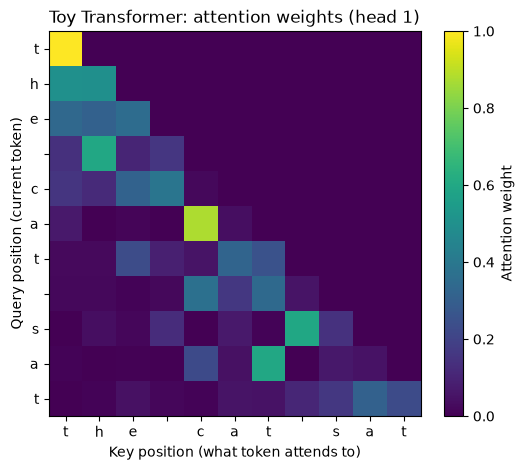

In [20]:
import matplotlib.pyplot as plt

model.eval()
prompt = "the cat sat"
ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
x = model.token_embedding(ids) + model.position_embedding(
    torch.arange(ids.shape[1], device=device)
)
block = model.blocks[0]
normalized_x = block.ln1(x)
_, weights = block.attention.heads[0](normalized_x)
attn = weights[0].detach().cpu().numpy()

plt.figure(figsize=(6, 5))
plt.imshow(attn, aspect="auto")
plt.xticks(range(len(prompt)), list(prompt))
plt.yticks(range(len(prompt)), list(prompt))
plt.xlabel("Key position (what token attends to)")
plt.ylabel("Query position (current token)")
plt.title("Toy Transformer: attention weights (head 1)")
plt.colorbar(label="Attention weight")
plt.show()